# 06. Explainability: SHAP and partial dependence

Why does the model forecast what it forecasts? This notebook opens the final-window LightGBM model
with **SHAP** (how much each feature pushed a prediction up or down) and **partial dependence**
(what happens to the forecast, on average, as one feature changes).

These explain the *model*, not the real world: a feature the model leans on is not necessarily a
cause of sales.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rossmann_forecast.config import DEFAULT_ORIGINS, HORIZON, MIN_LAG
from rossmann_forecast.data import load_panel
from rossmann_forecast.metrics import all_metrics, wape
from rossmann_forecast.plotting import COLORS, NAMES, apply_style, find_root
from rossmann_forecast.splits import rolling_origin_folds

apply_style()
ROOT = find_root()
panel = load_panel(ROOT / "data")
folds = rolling_origin_folds(DEFAULT_ORIGINS, HORIZON, panel.dates[-1])
final_fold = folds[-1]
print(f"{len(panel.stores):,} stores, {panel.dates[0].date()} to {panel.dates[-1].date()}")

1,115 stores, 2013-01-01 to 2015-07-31


## 1. Fit the model and pick rows to explain

In [2]:
import shap

from rossmann_forecast.features import build_features
from rossmann_forecast.models import fit_lightgbm, forecast_rows, training_rows

origin = final_fold.test_start
feats = build_features(panel, MIN_LAG, known_until=origin)
model = fit_lightgbm(training_rows(feats, origin))
test = forecast_rows(feats, origin, final_fold.test_end)
test = test[test["sales"].notna()]
X = test.sample(4000, random_state=42)[model.columns]
explainer = shap.TreeExplainer(model.model)
sv = explainer(X)
print(f"explained {len(X):,} store-days; values are in log1p(sales) units")

explained 4,000 store-days; values are in log1p(sales) units


## 2. Global importance

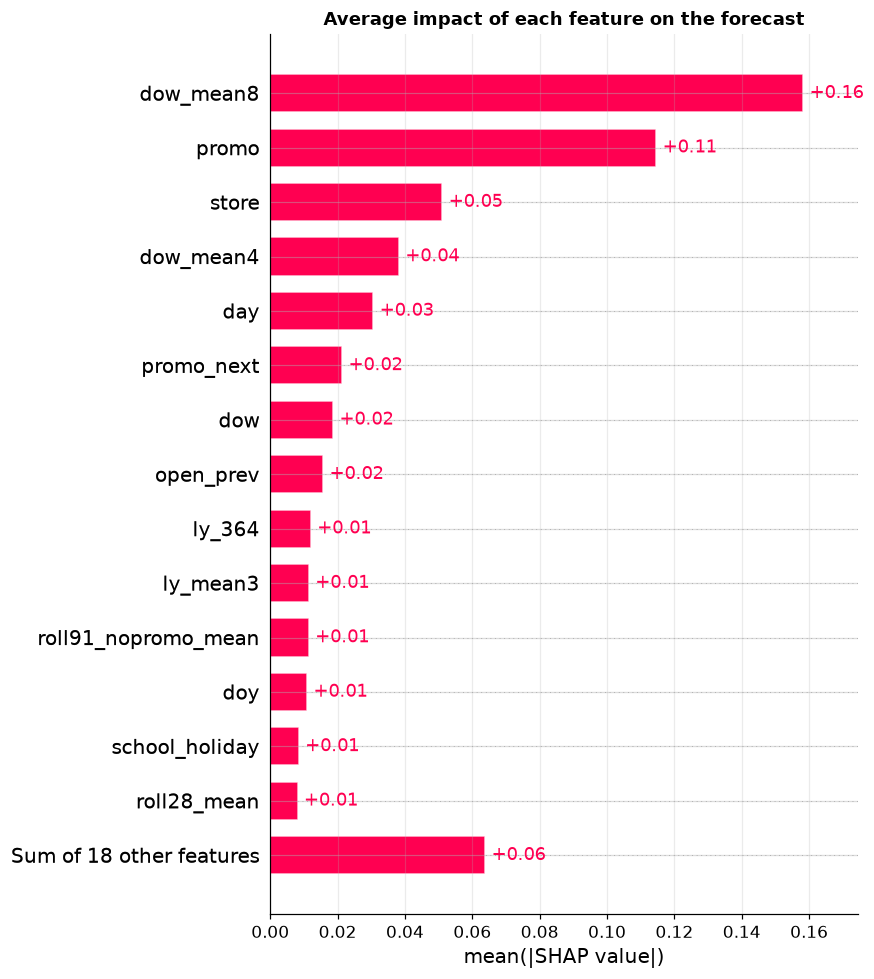

In [3]:
shap.plots.bar(sv, max_display=15, show=False)
plt.title("Average impact of each feature on the forecast")
plt.tight_layout()
plt.show()

Recent same-weekday sales (`dow_mean8`, `dow_mean4`) set each store's level, the promo flag moves
it, and `store` and calendar features adjust for store identity and timing.

## 3. Direction of impact

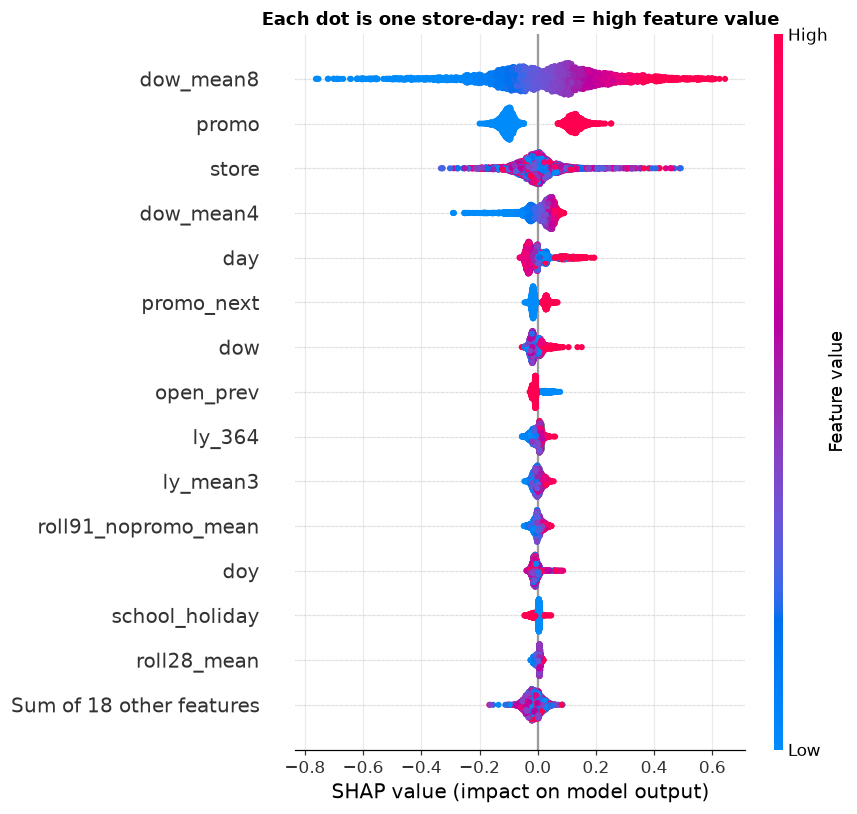

In [4]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("Each dot is one store-day: red = high feature value")
plt.tight_layout()
plt.show()

For `promo`, red dots (promo on) sit to the right: a promo pushes the forecast up. For
`dow_mean8`, high recent same-weekday sales push the forecast up, as expected.

## 4. One forecast, explained

Store 930 on 2015-07-13: actual 8,293, forecast 9,547


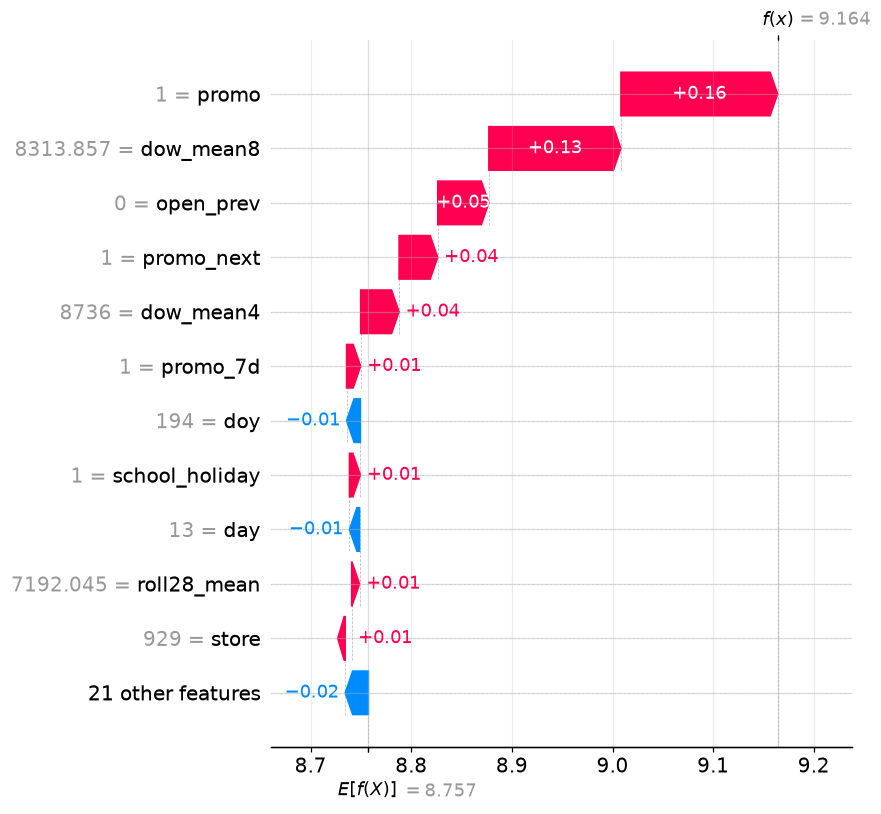

In [5]:
i = int(np.argsort(np.abs(sv.values).sum(axis=1))[len(X) // 2])
row_idx = X.index[i]
meta = test.loc[row_idx]
print(f"Store {int(meta['store_id'])} on {meta['date'].date()}: actual {meta['sales']:,.0f}, "
      f"forecast {np.expm1(sv.base_values[i] + sv.values[i].sum()):,.0f}")
shap.plots.waterfall(sv[i], max_display=12, show=False)
plt.tight_layout()
plt.show()

## 5. Dependence: how a feature changes the forecast

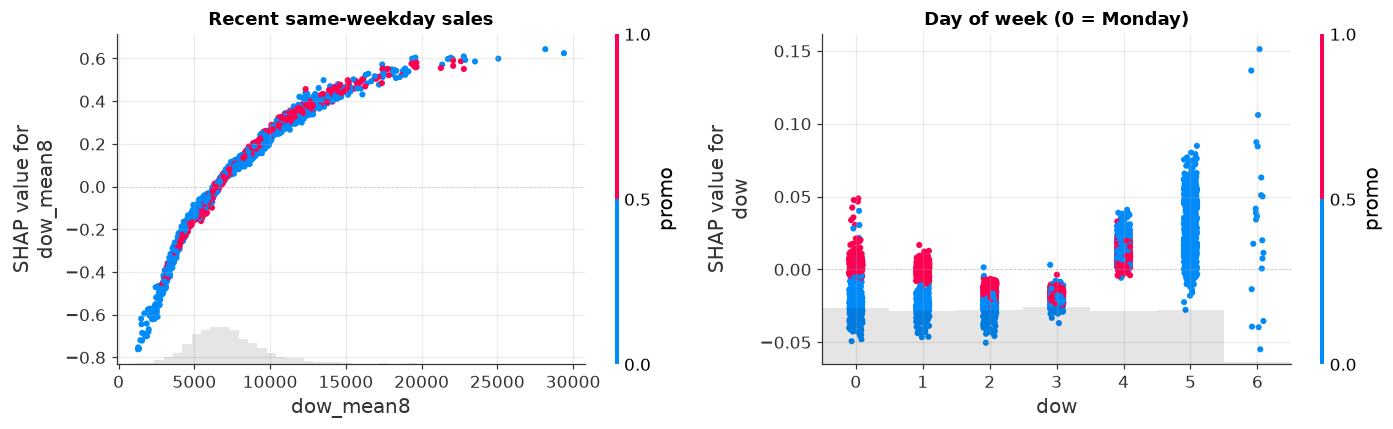

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
shap.plots.scatter(sv[:, "dow_mean8"], ax=axes[0], show=False, color=sv[:, "promo"])
axes[0].set_title("Recent same-weekday sales")
shap.plots.scatter(sv[:, "dow"], ax=axes[1], show=False, color=sv[:, "promo"])
axes[1].set_title("Day of week (0 = Monday)")
fig.tight_layout()
plt.show()

## 6. Partial dependence

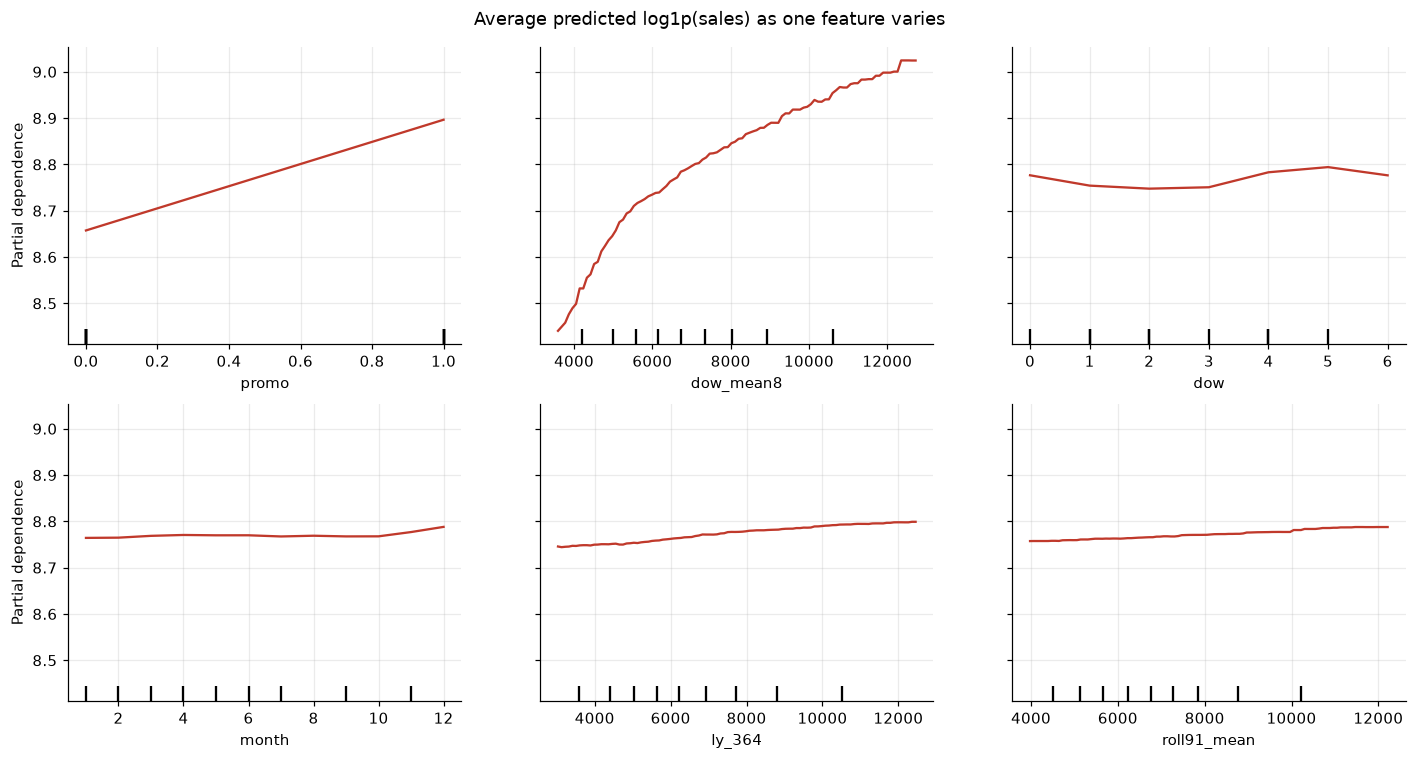

In [7]:
from sklearn.inspection import PartialDependenceDisplay

train = training_rows(feats, origin)
sample = train[train["date"] >= "2014-01-01"].dropna(subset=["ly_364"]).sample(8000, random_state=1)[model.columns].astype("float64")
fig, ax = plt.subplots(figsize=(13, 7))
PartialDependenceDisplay.from_estimator(
    model.model, sample, ["promo", "dow_mean8", "dow", "month", "ly_364", "roll91_mean"],
    ax=ax, n_cols=3, line_kw={"color": COLORS["lightgbm"]},
)
fig.suptitle("Average predicted log1p(sales) as one feature varies")
fig.tight_layout()
plt.show()

The promo curve steps up between 0 and 1. The same-weekday history (`dow_mean8`) carries most of
the forecast: a store's recent level passes straight through. The other history features are nearly
flat on their own because `dow_mean8` already holds that information, and the month effect is small
next to the differences between stores.